# Nivelación 0b — Probabilidad en el piso resbaloso

**RL a ciegas** · Nivelación 0b

En la nivelación 0a la cueva era **determinista**: la misma acción desde la misma casilla daba siempre el mismo resultado. Hoy le ponemos **piso resbaloso**: `CaveEnv(slip=0.2)` hace que, el 20 % de las veces, el agente se desvíe hacia uno de los dos costados. Con eso aparece el azar, y con el azar la **probabilidad**: el lenguaje que usa RL para todo.

Hoy vamos a ver:

1. **Espacio muestral y eventos**: ¿adónde puedo caer después de un paso?
2. **Variables aleatorias**: la posición después de un paso, los pasos hasta salir.
3. **Función de masa de probabilidad** (PMF) y **simulación**: la ley de los grandes números.
4. **Esperanza y varianza**: ¿cuánto tardo en promedio, y cuánto varía?
5. Dos distribuciones famosas: **Bernoulli** (¿choqué?) y **geométrica** (¿cuántos intentos hasta salir del callejón?).
6. Probabilidad **conjunta** y **condicional**: $P(s' \mid s, a)$ es una condicional.
7. **Regla de Bayes**: ¿dónde estoy, si acabo de chocar? (localización).
8. **Independencia** y el **supuesto de Markov**.
9. **Esperanza de una suma**: el retorno esperado, lo que el agente maximiza.

> Cómo usar este notebook: ejecutar las celdas en orden. Tarda menos de un minuto.

### Preparación

La primera celda escribe el entorno `cave_env.py` (el mismo que armamos a mano en la nivelación 0a). La segunda importa lo necesario.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


In [2]:
from cave_env import CaveEnv, ACTION_NAMES
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100

### Herramientas

Funciones para jugar partidas, simular un solo paso, calcular la "política que conoce el mapa" (la vamos a construir en la clase 4; hoy la usamos como caja negra) y dibujar varias cuevas lado a lado. **No hace falta leerla.**

In [3]:
# @title Herramientas (plegada)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe


def politica_con_mapa(gamma=0.95):
    '''La mejor flecha en cada casilla, calculada con el mapa (iteración de valores, clase 4).'''
    e = CaveEnv()
    V = np.zeros(e.nS)
    for _ in range(500):
        V = (e.R + gamma * e.P @ V).max(axis=1)
    return (e.R + gamma * e.P @ V).argmax(axis=1)


def un_paso(env, s, a, n, seed=0):
    '''Pone al agente en s, hace la acción a n veces (siempre desde s) y devuelve los destinos y los choques.'''
    env.rng = np.random.default_rng(seed)
    destinos, choques = np.empty(n, dtype=int), np.empty(n, dtype=bool)
    for i in range(n):
        env.s, env.t = s, 0
        s2, _, _, info = env.step(a)
        destinos[i], choques[i] = s2, info["bump"]
    return destinos, choques


def jugar(env, policy, seed=0, max_steps=500):
    '''Una partida desde S siguiendo la política. Devuelve (pasos, llegó, camino).'''
    env.rng = np.random.default_rng(seed)
    env.max_steps = max_steps
    s = env.reset(); camino = [s]
    done = False
    while not done:
        s, r, done, info = env.step(int(policy[s]))
        camino.append(s)
    return len(camino) - 1, info["reached_goal"], camino


def modelo_observacion(env):
    '''M[s, a, s2, o] = P(llego a s2 y observo o | estoy en s y hago a), con o = 1 si choqué.'''
    M = np.zeros((env.nS, env.nA, env.nS, 2))
    for s in range(env.nS):
        for a in range(env.nA):
            if s == env.goal:
                M[s, a, s, 0] = 1.0
                continue
            salidas = [(a, 1 - env.slip)]
            if env.slip > 0:
                salidas += [((a + 1) % 4, env.slip / 2), ((a + 3) % 4, env.slip / 2)]
            for aa, p in salidas:
                s2, bump = env._move(s, aa)
                M[s, a, s2, int(bump)] += p
    return M


def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None,
              cmap="magma", clim=None, mark=None, numbers=False):
    '''env.plot con flechas remarcadas, escala de color elegible y un círculo opcional en la casilla mark.'''
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None and clim is not None:
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        r, c = env.free[mark]
        ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if values[s] > 0 and s != env.goal:
                ax.text(c, r + 0.33, f"{values[s]:.1f}", ha="center", va="center", fontsize=8, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_row(env, values_list, titles, cmap="magma", clim=None, marks=None, paths=None, size=4.0, ncols=None):
    '''Varias cuevas lado a lado (en varias filas si se pasa ncols).'''
    n = len(values_list)
    ncols = n if ncols is None else ncols
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, (size * env.H / env.W + 0.7) * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    for i, ax in enumerate(axes[:n]):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap, clim=clim,
                  mark=None if marks is None else marks[i], path=None if paths is None else paths[i])
    plt.tight_layout(); plt.show()


def nombre(env, s):
    return "(%d,%d)" % env.free[s]

## Paso 1 — Espacio muestral y eventos: ¿adónde puedo caer?

Hacemos un **experimento aleatorio** (*random experiment*): parados en el inicio **S**, intentamos ir hacia abajo (↓) con piso resbaloso (`slip=0.2`). Hay tres resultados posibles:

- no me resbalo y bajo (probabilidad 0,8);
- me resbalo hacia la derecha y me muevo a la derecha (0,1);
- me resbalo hacia la izquierda, choco contra la pared y me quedo en S (0,1).

Miremos esas probabilidades pintadas sobre la cueva (el color y el número de cada casilla son $P(s' \mid s{=}S, a{=}{\downarrow})$; las casillas imposibles quedan en negro).

llego a (1,1)  con probabilidad 0.10
llego a (1,2)  con probabilidad 0.10
llego a (2,1)  con probabilidad 0.80


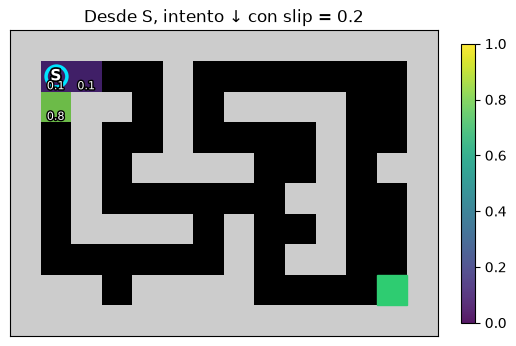

In [4]:
env = CaveEnv(slip=0.2)
S, ABAJO = env.start, 2
p = env.P[S, ABAJO]
for s2 in np.flatnonzero(p):
    print(f"llego a {nombre(env, s2)}  con probabilidad {p[s2]:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.3))
plot_cave(env, values=np.where(p > 0, p, np.nan), cmap="viridis", ax=ax, clim=(0, 1), mark=S,
          numbers=True, title="Desde S, intento ↓ con slip = 0.2")
plt.show()

Ahora las palabras:

- El **espacio muestral** $\Omega$ es el conjunto de todos los resultados posibles: $\Omega = \{$bajo, me corro a la derecha, choco$\}$.
- Un **evento** es un subconjunto de $\Omega$. Por ejemplo $A =$ "me muevo" $= \{$bajo, me corro a la derecha$\}$, y su **complemento** $A^c =$ "choco".
- Una **probabilidad** le asigna a cada evento un número entre 0 y 1, con $P(\Omega) = 1$ y, para eventos que no se pisan (disjuntos), $P(A \cup B) = P(A) + P(B)$.

Por eso $P(\text{me muevo}) = 0{,}8 + 0{,}1 = 0{,}9$ y $P(\text{choco}) = 1 - P(\text{me muevo}) = 0{,}1$.

## Paso 2 — Variables aleatorias

Una **variable aleatoria** es un número que depende del resultado del experimento. Dos que vamos a usar todo el curso:

- $X$ = **la casilla donde quedo** después de un paso (en `CaveEnv` es directamente un número de estado);
- $N$ = **cuántos pasos tardo en salir** de la cueva siguiendo una política fija.

Juguemos 5 partidas con la política que conoce el mapa, con `slip=0.3`. La política es siempre la misma, pero $N$ cambia de partida en partida: es aleatoria.

partida 0:  N = 28 pasos
partida 1:  N = 29 pasos
partida 2:  N = 30 pasos
partida 3:  N = 35 pasos
partida 4:  N = 25 pasos


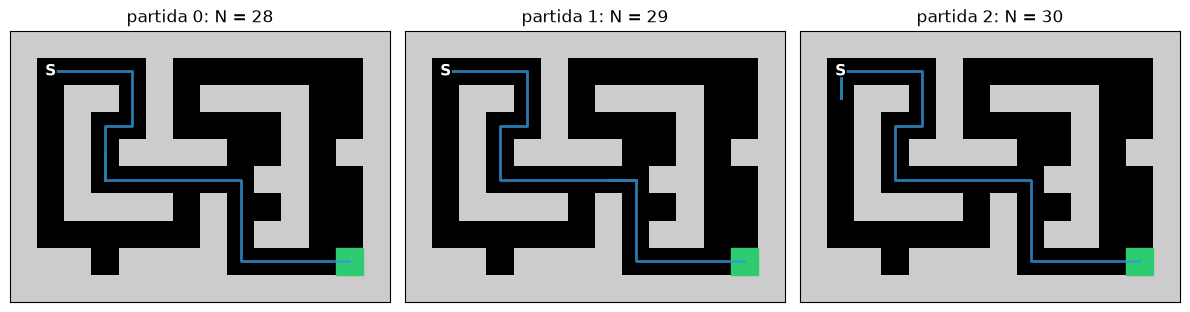

In [5]:
pi = politica_con_mapa()
env3 = CaveEnv(slip=0.3)
resultados = [jugar(env3, pi, seed=k) for k in range(5)]
for k, (N, llego, _) in enumerate(resultados):
    print(f"partida {k}:  N = {N} pasos")

plot_row(env3, [None, None, None], [f"partida {k}: N = {resultados[k][0]}" for k in range(3)],
         paths=[resultados[k][2] for k in range(3)])

Sin resbalones la salida está a exactamente 20 pasos. Cada resbalón agrega un desvío (casi siempre un choque contra la pared del pasillo, que hace perder un turno), así que $N \geq 20$ y varía.

## Paso 3 — PMF y simulación: las frecuencias se acercan a las probabilidades

La **función de masa de probabilidad** (*probability mass function*, PMF) de una variable discreta dice cuánto vale $P(X = x)$ para cada valor $x$. Para $X$ = "dónde quedo" desde S con ↓, la PMF es la del Paso 1: $0{,}8$, $0{,}1$ y $0{,}1$.

Si no conociéramos esa PMF, podríamos **estimarla jugando**: repetir el paso muchas veces y contar. Veamos qué pasa con 10, 100, 1000 y 10000 repeticiones (barras = frecuencias observadas, puntos negros = probabilidad verdadera).

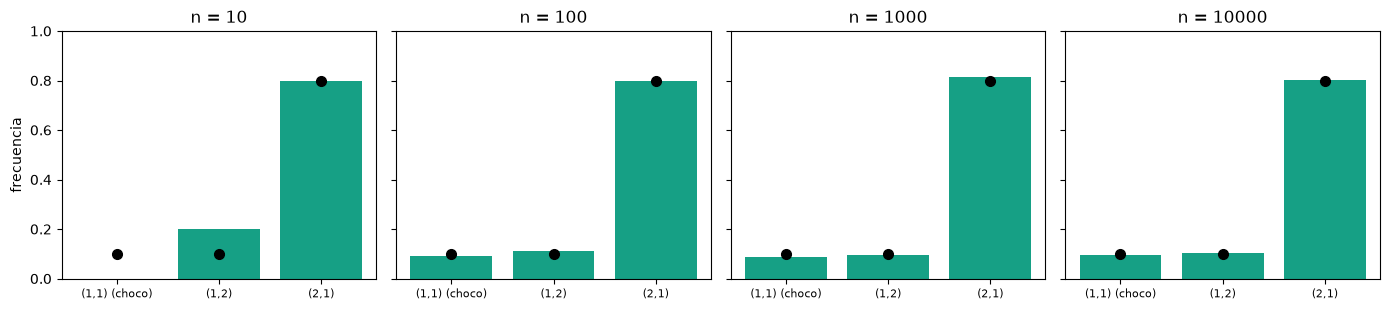

In [6]:
destinos, choques = un_paso(env, S, ABAJO, n=10_000, seed=1)
posibles = np.flatnonzero(p)
etiquetas = [nombre(env, s2) + (" (choco)" if s2 == S else "") for s2 in posibles]

fig, axs = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, n in zip(axs, [10, 100, 1000, 10_000]):
    frec = [(destinos[:n] == s2).mean() for s2 in posibles]
    ax.bar(etiquetas, frec, color="#16a085")
    ax.plot(etiquetas, p[posibles], "ko", ms=7)
    ax.set_title(f"n = {n}"); ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelsize=8)
axs[0].set_ylabel("frecuencia")
plt.tight_layout(); plt.show()

Con 10 repeticiones las barras están lejos de los puntos; con 10000 casi los tocan. Miremos lo mismo como curva: la **fracción acumulada de choques** a medida que repetimos, para tres corridas distintas.

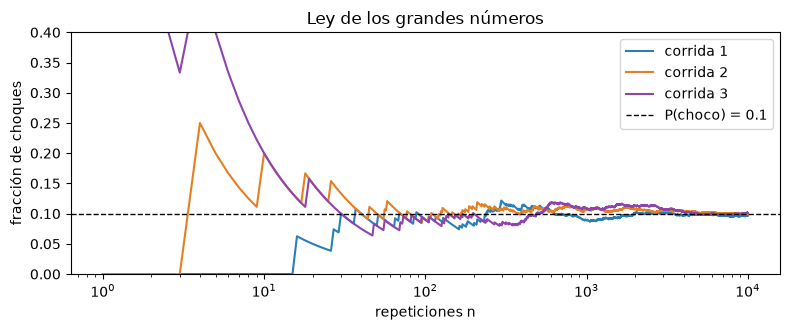

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
n = np.arange(1, 10_001)
for semilla, col in zip([1, 2, 3], ["#2980b9", "#e67e22", "#8e44ad"]):
    _, ch = un_paso(env, S, ABAJO, n=10_000, seed=semilla)
    ax.plot(n, np.cumsum(ch) / n, color=col, lw=1.5, label=f"corrida {semilla}")
ax.axhline(0.1, color="k", ls="--", lw=1, label="P(choco) = 0.1")
ax.set_xscale("log"); ax.set_ylim(0, 0.4)
ax.set_xlabel("repeticiones n"); ax.set_ylabel("fracción de choques")
ax.set_title("Ley de los grandes números"); ax.legend(); plt.tight_layout(); plt.show()

Esto es la **ley de los grandes números**: el promedio de muchas repeticiones independientes se acerca al valor esperado. Es la base de todo lo que hace RL *sin modelo* (clases 5 y 6): el agente no conoce $P$, pero puede promediar lo que le pasa.

## Paso 4 — Esperanza y varianza: ¿cuánto tardo en salir?

Volvamos a $N$, los pasos hasta salir con la política que conoce el mapa. Juguemos 2000 partidas con tres pisos distintos y miremos la distribución de $N$.

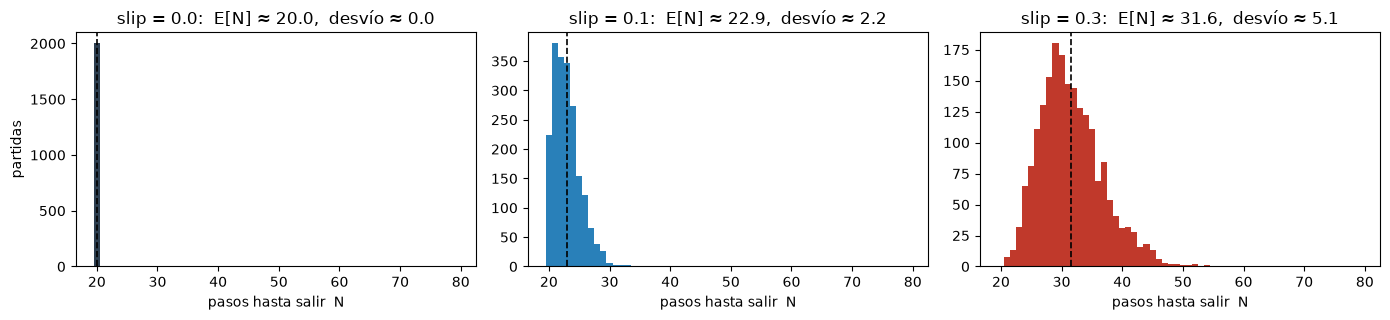

In [8]:
slips = [0.0, 0.1, 0.3]
N_por_slip = {}
for sl in slips:
    e = CaveEnv(slip=sl)
    N_por_slip[sl] = np.array([jugar(e, pi, seed=k)[0] for k in range(2000)])

fig, axs = plt.subplots(1, 3, figsize=(14, 3.3), sharex=True)
for ax, sl, col in zip(axs, slips, ["#2c3e50", "#2980b9", "#c0392b"]):
    Ns = N_por_slip[sl]
    ax.hist(Ns, bins=np.arange(19.5, 80.5, 1), color=col)
    ax.axvline(Ns.mean(), color="k", ls="--", lw=1.2)
    ax.set_title(f"slip = {sl}:  E[N] ≈ {Ns.mean():.1f},  desvío ≈ {Ns.std():.1f}")
    ax.set_xlabel("pasos hasta salir  N")
axs[0].set_ylabel("partidas")
plt.tight_layout(); plt.show()

Más resbaloso → el histograma se corre a la derecha (**tardo más en promedio**) y se ensancha (**es más impredecible**). Esas dos ideas tienen nombre:

$$\mathbb{E}[N] = \sum_n n\, P(N = n) \qquad\qquad \mathrm{Var}(N) = \mathbb{E}\big[(N - \mathbb{E}[N])^2\big]$$

La **esperanza** es el centro de masa del histograma (la línea punteada). La **varianza** mide cuánto se desparrama alrededor; su raíz, el **desvío estándar**, está en las mismas unidades que $N$ (pasos). Con `slip = 0` la varianza es 0: siempre son 20 pasos.

In [9]:
for sl in slips:
    Ns = N_por_slip[sl]
    print(f"slip = {sl}:  E[N] ≈ {Ns.mean():5.1f}   Var(N) ≈ {Ns.var():6.1f}   desvío ≈ {Ns.std():4.1f}   máximo = {Ns.max()}")

slip = 0.0:  E[N] ≈  20.0   Var(N) ≈    0.0   desvío ≈  0.0   máximo = 20
slip = 0.1:  E[N] ≈  22.9   Var(N) ≈    4.9   desvío ≈  2.2   máximo = 33
slip = 0.3:  E[N] ≈  31.6   Var(N) ≈   26.3   desvío ≈  5.1   máximo = 54


## Paso 5 — Bernoulli y geométrica

**Bernoulli.** La variable más simple: vale 1 con probabilidad $p$ y 0 con probabilidad $1 - p$. "¿Choqué en este paso?" es una Bernoulli. Su esperanza es $p$ y su varianza $p(1-p)$. Lo comprobamos con las 10000 repeticiones del Paso 3 (desde S con ↓, $p = 0{,}1$):

In [10]:
print(f"media de 'choqué':     {choques.mean():.4f}   (teoría: p = 0.1)")
print(f"varianza de 'choqué':  {choques.var():.4f}   (teoría: p(1-p) = {0.1 * 0.9:.4f})")

media de 'choqué':     0.0965   (teoría: p = 0.1)
varianza de 'choqué':  0.0872   (teoría: p(1-p) = 0.0900)


**Geométrica.** Repetimos un intento de Bernoulli hasta el primer éxito y contamos cuántos intentos hicieron falta. En la cueva hay un **callejón sin salida** en la casilla (8, 3): tiene pared abajo, a la izquierda y a la derecha. Un agente que elige acciones al azar sale del callejón solo si elige ↑: probabilidad $p = 1/4$ en cada intento. ¿Cuántos intentos necesita?

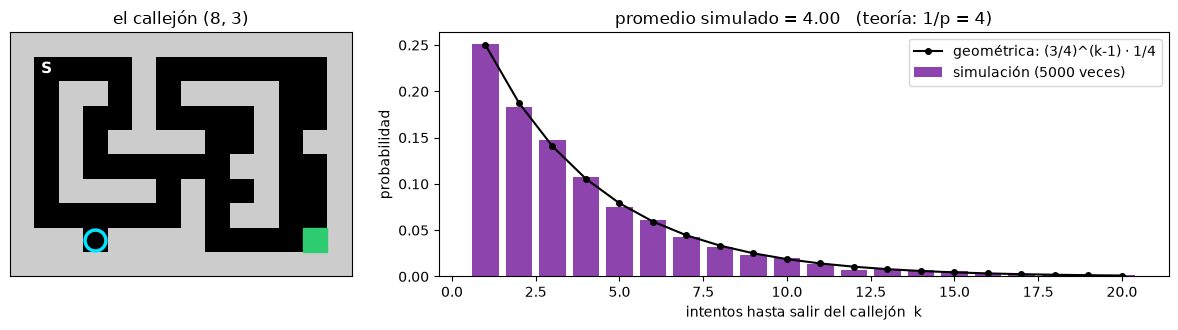

In [11]:
env0 = CaveEnv(slip=0.0, seed=4)
callejon = env0.pos2s[(8, 3)]
rng = np.random.default_rng(4)
intentos = []
for _ in range(5000):
    env0.s, env0.t, k = callejon, 0, 0
    while env0.s == callejon:
        env0.step(int(rng.integers(4))); k += 1
    intentos.append(k)
intentos = np.array(intentos)

kk = np.arange(1, 21)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 2]})
plot_cave(env0, ax=axs[0], mark=callejon, title="el callejón (8, 3)")
axs[1].bar(kk, [(intentos == x).mean() for x in kk], color="#8e44ad", label="simulación (5000 veces)")
axs[1].plot(kk, (3 / 4) ** (kk - 1) * (1 / 4), "ko-", ms=4, label="geométrica: (3/4)^(k-1) · 1/4")
axs[1].set_xlabel("intentos hasta salir del callejón  k"); axs[1].set_ylabel("probabilidad")
axs[1].set_title(f"promedio simulado = {intentos.mean():.2f}   (teoría: 1/p = 4)"); axs[1].legend()
plt.tight_layout(); plt.show()

La PMF geométrica es $P(K = k) = (1-p)^{k-1}\, p$: fallar $k-1$ veces y acertar una. Su esperanza es $1/p$. Es la matemática de la **recompensa escasa** (la nombramos en la clase 2; cómo explorar cuando escasea, en la clase 7): si un agente al azar encuentra la salida con probabilidad $p$ pequeña por partida, va a necesitar del orden de $1/p$ partidas para verla una sola vez.

## Paso 6 — Probabilidad conjunta y condicional

Ahora hay **dos** cosas aleatorias: la acción $a$ (el agente elige al azar, $\pi(a) = 1/4$) y la casilla $s'$ donde termina (por el piso resbaloso). Parados en S, la tabla siguiente es la **probabilidad conjunta** $P(a, s')$: la chance de que pasen las dos cosas a la vez. Toda la tabla suma 1.

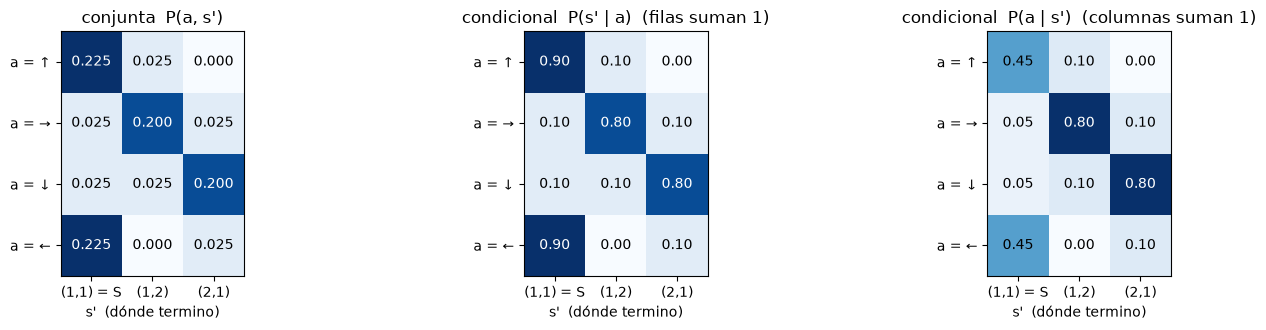

marginal P(a)  = suma de cada fila:    [0.25 0.25 0.25 0.25]
marginal P(s') = suma de cada columna: [0.5  0.25 0.25]


In [12]:
pi_azar = np.full(4, 0.25)
conj = pi_azar[:, None] * env.P[S]            # (4 acciones, 60 casillas)
cols = np.flatnonzero(conj.sum(axis=0))       # solo las casillas alcanzables
tabla = conj[:, cols]

def dibujar_tabla(T, titulo, ax, fmt="{:.3f}"):
    ax.imshow(T, cmap="Blues", vmin=0, vmax=max(T.max(), 1e-9))
    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            ax.text(j, i, fmt.format(T[i, j]), ha="center", va="center",
                    color="w" if T[i, j] > 0.6 * T.max() else "k", fontsize=10)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([nombre(env, s2) + (" = S" if s2 == S else "") for s2 in cols])
    ax.set_yticks(range(4)); ax.set_yticklabels([f"a = {n}" for n in ACTION_NAMES])
    ax.set_xlabel("s'  (dónde termino)"); ax.set_title(titulo)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
dibujar_tabla(tabla, "conjunta  P(a, s')", axs[0])
dibujar_tabla(tabla / tabla.sum(axis=1, keepdims=True), "condicional  P(s' | a)  (filas suman 1)", axs[1], "{:.2f}")
dibujar_tabla(tabla / tabla.sum(axis=0, keepdims=True), "condicional  P(a | s')  (columnas suman 1)", axs[2], "{:.2f}")
plt.tight_layout(); plt.show()

print("marginal P(a)  = suma de cada fila:   ", tabla.sum(axis=1).round(3))
print("marginal P(s') = suma de cada columna:", tabla.sum(axis=0).round(3))

Las tres tablas tienen los mismos números, **normalizados de otra forma**:

$$P(s' \mid a) = \frac{P(a, s')}{P(a)} \qquad\qquad P(a \mid s') = \frac{P(a, s')}{P(s')}$$

- **Condicional** = "me restrinjo a una fila (o columna) y la vuelvo a escalar para que sume 1".
- **Marginal** = "sumo lo que no me interesa".

La tabla del medio es exactamente `env.P[S]`: **el modelo de transición $P(s' \mid s, a)$ de un MDP es una probabilidad condicional**. La de la derecha da vuelta la pregunta: "terminé en S, ¿qué acción habré hecho?" (la mitad de las veces ↑, la otra mitad ←: las dos chocan). Dar vuelta una condicional es la regla de Bayes.

## Paso 7 — Regla de Bayes: ¿dónde estoy, si acabo de chocar?

Cambiemos el juego: el agente **tiene el mapa** pero **no sabe dónde está** (lo despertaron en una casilla cualquiera, a oscuras). Su **creencia** (*belief*) es una probabilidad sobre las casillas; al principio, todas iguales.

Hace → y **choca**. ¿Dónde puede estar? Solo en casillas que tienen pared a la derecha. Veamos de izquierda a derecha: la creencia **antes** (*prior*), la **verosimilitud** (*likelihood*) $P(\text{choco} \mid s, \rightarrow)$ y la creencia **después** (*posterior*). Piso no resbaloso, por ahora.

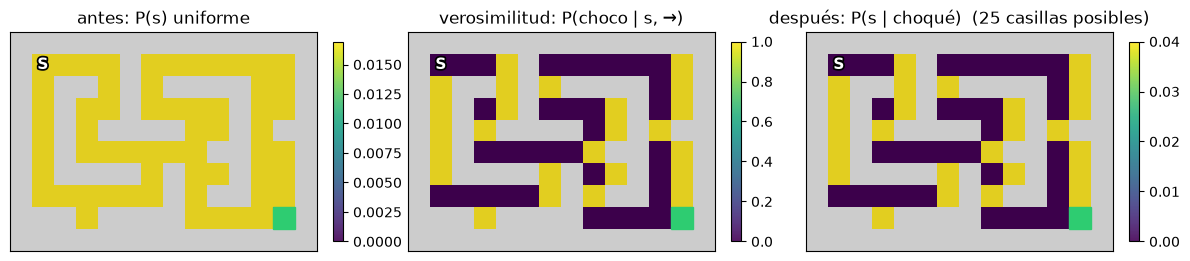

In [13]:
env0 = CaveEnv(slip=0.0)
M0 = modelo_observacion(env0)
DER = 1
no_meta = np.arange(env0.nS) != env0.goal

prior = no_meta / no_meta.sum()                   # uniforme sobre las casillas (menos la salida)
verosim = M0[:, DER, :, 1].sum(axis=1)            # P(choco | s, →)
posterior = prior * verosim
posterior /= posterior.sum()

plot_row(env0, [prior, verosim, posterior],
         ["antes: P(s) uniforme", "verosimilitud: P(choco | s, →)", f"después: P(s | choqué)  ({(posterior > 0).sum()} casillas posibles)"],
         cmap="viridis")

La cuenta es la **regla de Bayes**:

$$P(s \mid \text{choqué}) = \frac{P(\text{choqué} \mid s)\; P(s)}{P(\text{choqué})}, \qquad P(\text{choqué}) = \sum_{s} P(\text{choqué} \mid s)\, P(s)$$

"Después ∝ verosimilitud × antes", y el denominador solo normaliza para que sume 1.

Un choque solo no alcanza para saber dónde estoy. Pero el agente puede **seguir moviéndose y observando**: después de cada paso, primero mueve su creencia según la acción ($P(s' \mid s, a)$) y después la corrige con Bayes según si chocó o no. Esto se llama **filtro de Bayes** (*Bayes filter*), y es lo que usan los robots para localizarse. Abajo, el agente empieza en la casilla del círculo celeste (que él no conoce) y sigue una regla simple: "avanzo en una dirección hasta chocar, después giro".

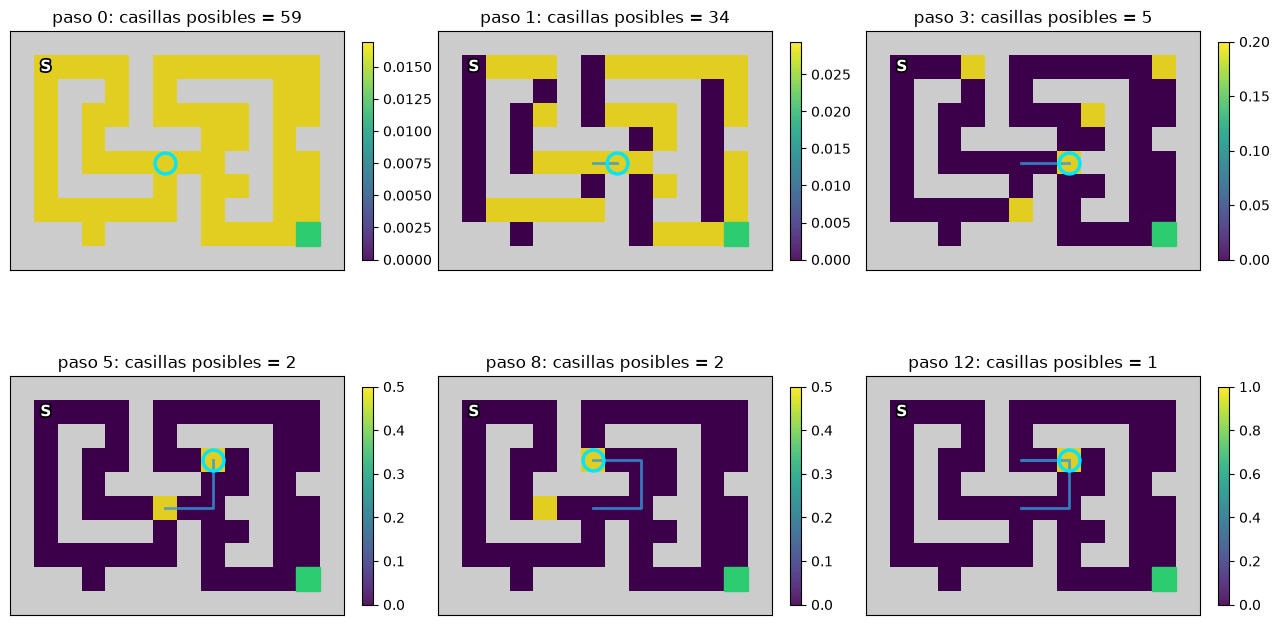

In [14]:
def filtro(env, M, creencia, a, choque):
    '''Un paso del filtro de Bayes: predecir con P(s'|s,a) y corregir con la observación.'''
    nueva = (creencia[:, None] * M[:, a, :, int(choque)]).sum(axis=0)
    return nueva / nueva.sum()

def localizar(env, M, inicio_real, n_pasos, seed=0):
    env.rng = np.random.default_rng(seed)
    env.s, env.t = inicio_real, 0
    b = no_meta / no_meta.sum()
    creencias, verdad, a = [b], [inicio_real], 1
    for _ in range(n_pasos):
        _, _, _, info = env.step(a)
        b = filtro(env, M, b, a, info["bump"])
        creencias.append(b); verdad.append(env.s)
        if info["bump"]:
            a = (a + 3) % 4          # giro a la izquierda (en sentido antihorario)
    return creencias, verdad

inicio_real = env0.pos2s[(5, 6)]
creencias, verdad = localizar(env0, M0, inicio_real, n_pasos=12)
pasos_a_ver = [0, 1, 3, 5, 8, 12]
plot_row(env0, [creencias[t] for t in pasos_a_ver],
         [f"paso {t}: casillas posibles = {(creencias[t] > 1e-9).sum()}" for t in pasos_a_ver],
         cmap="viridis", clim=(0, None), marks=[verdad[t] for t in pasos_a_ver],
         paths=[verdad[:t + 1] for t in pasos_a_ver], size=4.3, ncols=3)

Cada paño es la creencia después de $t$ pasos (más claro = más probable); el círculo celeste es la posición real y la línea azul el recorrido. Paso a paso, las casillas incompatibles con lo que el agente sintió se apagan, hasta que la creencia se concentra en el lugar correcto.

Esto conecta con el juego: el jugador real tampoco ve dónde está; lo único que "siente" son los choques. Si el agente no conoce su posición, su **estado** ya no es la casilla sino algo como esta creencia. En la clase 2 lo anticipamos y en la 9 lo vemos a fondo.

## Paso 8 — Independencia y el supuesto de Markov

Dos eventos son **independientes** si saber uno no cambia la probabilidad del otro: $P(A \mid B) = P(A)$, o lo que es lo mismo, $P(A \cap B) = P(A)\,P(B)$. En `CaveEnv`, cada resbalón se sortea **de nuevo** en cada paso, sin mirar el pasado.

De ahí sale una propiedad clave: el **supuesto de Markov**. Adónde voy depende solo de **dónde estoy y qué hago ahora**, no de cómo llegué:

$$P(s_{t+1} \mid s_t, a_t, s_{t-1}, a_{t-1}, \dots) = P(s_{t+1} \mid s_t, a_t)$$

Lo comprobamos jugando: un agente al azar camina 300 mil pasos por la cueva resbalosa. Juntamos todas las veces que estuvo en la casilla (3, 4) e hizo ↑, y las separamos según **de dónde venía**. Si el pasado importara, las barras de cada grupo serían distintas.

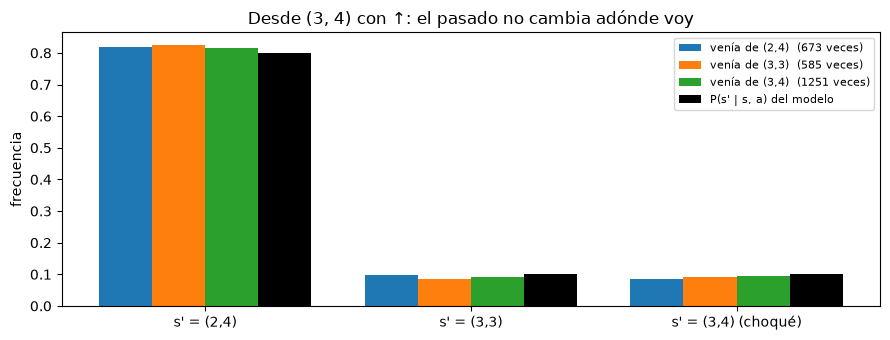

In [15]:
envm = CaveEnv(slip=0.2, seed=5, max_steps=10**9)
rng = np.random.default_rng(5)
X, ARRIBA = envm.pos2s[(3, 4)], 0
previo, s = envm.reset(), envm.reset()
datos = []                         # (de dónde venía, adónde fue)
for _ in range(300_000):
    a = int(rng.integers(4))
    s2, _, done, _ = envm.step(a)
    if s == X and a == ARRIBA:
        datos.append((previo, s2))
    previo, s = s, s2
    if done:
        previo = s = envm.reset()
datos = np.array(datos)

destinos = np.flatnonzero(envm.P[X, ARRIBA])
origenes = [o for o in np.unique(datos[:, 0]) if (datos[:, 0] == o).sum() > 100]
ancho = 0.8 / (len(origenes) + 1)
fig, ax = plt.subplots(figsize=(9, 3.5))
for i, o in enumerate(origenes):
    sub = datos[datos[:, 0] == o, 1]
    ax.bar(np.arange(len(destinos)) + i * ancho, [(sub == d).mean() for d in destinos], ancho,
           label=f"venía de {nombre(envm, o)}  ({len(sub)} veces)")
ax.bar(np.arange(len(destinos)) + len(origenes) * ancho, envm.P[X, ARRIBA, destinos], ancho,
       color="k", label="P(s' | s, a) del modelo")
ax.set_xticks(np.arange(len(destinos)) + 0.4 - ancho / 2)
ax.set_xticklabels([f"s' = {nombre(envm, d)}" + (" (choqué)" if d == X else "") for d in destinos])
ax.set_ylabel("frecuencia"); ax.set_title("Desde (3, 4) con ↑: el pasado no cambia adónde voy")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Todas las barras de un mismo destino miden lo mismo (salvo ruido): **de dónde venía no importa**. La casilla actual resume todo lo necesario. Ojo: esto vale porque *nosotros* sabemos en qué casilla está el agente. Para el jugador a ciegas, que no lo sabe, la historia sí importa (lo anticipa la clase 2 y lo desarrolla la 9).

## Paso 9 — Esperanza de una suma: el retorno

En RL el agente no quiere la recompensa de un paso, sino la **suma descontada** de todas: el **retorno** (*return*)

$$G = r_1 + \gamma\, r_2 + \gamma^2 r_3 + \dots = \sum_{t \ge 0} \gamma^t\, r_{t+1}, \qquad 0 \le \gamma < 1.$$

En la cueva la única recompensa es +1 al entrar a la salida, así que si salgo en el paso $N$, $G = \gamma^{N-1}$: **cuanto antes salgo, más vale**. $G$ es una variable aleatoria (porque $N$ lo es). La propiedad más útil de la esperanza es que **es lineal**, también para sumas:

$$\mathbb{E}[G] = \sum_{t \ge 0} \gamma^t\, \mathbb{E}[r_{t+1}] = \sum_{t \ge 0} \gamma^t\, P(\text{salgo justo en el paso } t+1).$$

O sea: podemos calcular $\mathbb{E}[G]$ **sin jugar**, si sabemos con qué probabilidad salgo en cada paso. Esa probabilidad se obtiene empujando la distribución de "dónde estoy" un paso por vez con $P$ (es un producto matriz-vector: el tema de la nivelación 0c). Comparemos con el promedio de las 2000 partidas del Paso 4.

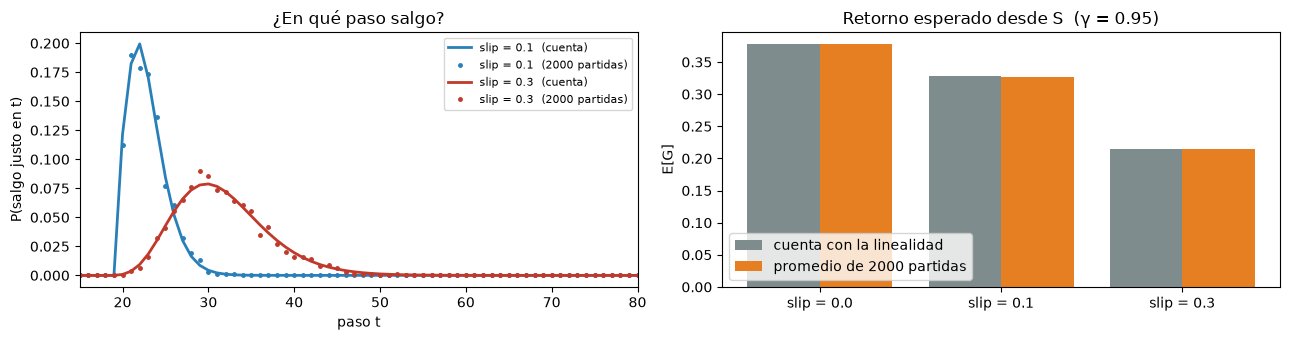

slip = 0.0:  E[G] cuenta = 0.3774   simulado = 0.3774
slip = 0.1:  E[G] cuenta = 0.3281   simulado = 0.3266
slip = 0.3:  E[G] cuenta = 0.2144   simulado = 0.2154


In [16]:
gamma = 0.95

def prob_salir_en_cada_paso(env, policy, T=500):
    P_pi = env.P[np.arange(env.nS), policy]          # (60, 60): adónde voy siguiendo la política
    d = np.zeros(env.nS); d[env.start] = 1.0         # al principio estoy en S
    en_meta = [0.0]
    for _ in range(T):
        d = d @ P_pi                                  # un paso de la distribución
        en_meta.append(d[env.goal])
    return np.diff(en_meta)                           # P(llego justo en el paso t+1)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
EG_exacta, EG_sim = [], []
for sl, col in zip(slips, ["#2c3e50", "#2980b9", "#c0392b"]):
    q = prob_salir_en_cada_paso(CaveEnv(slip=sl), pi)
    EG_exacta.append(np.sum(gamma ** np.arange(len(q)) * q))
    EG_sim.append(np.mean(gamma ** (N_por_slip[sl] - 1)))
    if sl > 0:
        axs[0].plot(np.arange(1, len(q) + 1), q, "-", color=col, lw=2, label=f"slip = {sl}  (cuenta)")
        Ns = N_por_slip[sl]
        axs[0].plot(np.arange(1, 81), [(Ns == t).mean() for t in range(1, 81)], ".", color=col, ms=5,
                    label=f"slip = {sl}  (2000 partidas)")
axs[0].set_xlim(15, 80); axs[0].set_xlabel("paso t"); axs[0].set_ylabel("P(salgo justo en t)")
axs[0].set_title("¿En qué paso salgo?"); axs[0].legend(fontsize=8)

xx = np.arange(len(slips))
axs[1].bar(xx - 0.2, EG_exacta, 0.4, color="#7f8c8d", label="cuenta con la linealidad")
axs[1].bar(xx + 0.2, EG_sim, 0.4, color="#e67e22", label="promedio de 2000 partidas")
axs[1].set_xticks(xx); axs[1].set_xticklabels([f"slip = {sl}" for sl in slips])
axs[1].set_ylabel("E[G]"); axs[1].set_title(f"Retorno esperado desde S  (γ = {gamma})"); axs[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

for sl, a, b in zip(slips, EG_exacta, EG_sim):
    print(f"slip = {sl}:  E[G] cuenta = {a:.4f}   simulado = {b:.4f}")

Las dos formas coinciden: la cuenta (linealidad de la esperanza) y el promedio de partidas (ley de los grandes números). Y el piso resbaloso **baja** el retorno esperado, porque demora la salida.

Ese número, el **retorno esperado desde una casilla siguiendo una política**, es exactamente lo que en la clase 3 vamos a llamar **valor** $V^\pi(s)$. Y es lo que el agente quiere **maximizar**: todo RL es buscar la política con el mayor retorno esperado.

## ✍️ Ejercicio 1 — Piso más resbaloso

Cambiá `slip_ej` (probá 0,5 y 0,7). ¿Cómo cambian $\mathbb{E}[N]$, el desvío y $\mathbb{E}[G]$? ¿Crece el desvío más rápido o más lento que la media?

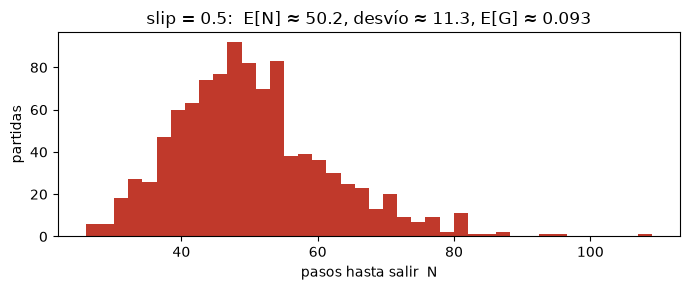

In [17]:
slip_ej = 0.5   # TODO: probá 0.5 y 0.7

e_ej = CaveEnv(slip=slip_ej)
Ns_ej = np.array([jugar(e_ej, pi, seed=k, max_steps=2000)[0] for k in range(1000)])
plt.figure(figsize=(7, 3))
plt.hist(Ns_ej, bins=40, color="#c0392b")
plt.xlabel("pasos hasta salir  N"); plt.ylabel("partidas")
plt.title(f"slip = {slip_ej}:  E[N] ≈ {Ns_ej.mean():.1f}, desvío ≈ {Ns_ej.std():.1f}, "
          f"E[G] ≈ {np.mean(gamma ** (Ns_ej - 1)):.3f}")
plt.tight_layout(); plt.show()

## ✍️ Ejercicio 2 — Localizarse con el piso resbaloso

Cambiá `inicio_ej` (cualquier casilla libre, por ejemplo `(1, 9)` o `(7, 1)`) y `slip_loc` (probá 0,1). Con piso resbaloso el agente ya no sabe con certeza si se movió: ¿tarda más en localizarse? ¿la creencia queda más "borrosa"?

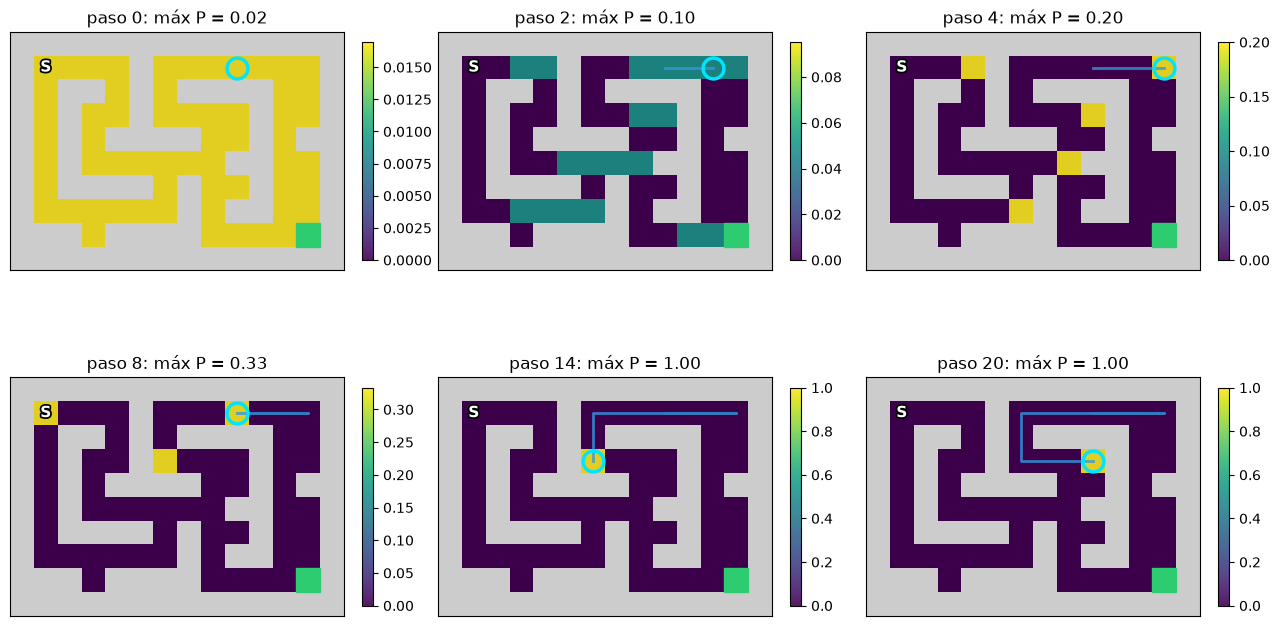

In [18]:
inicio_ej = (1, 9)   # TODO: probá otras casillas libres
slip_loc = 0.0       # TODO: probá 0.1

e_loc = CaveEnv(slip=slip_loc)
cre, ver = localizar(e_loc, modelo_observacion(e_loc), e_loc.pos2s[inicio_ej], n_pasos=20, seed=1)
ts = [0, 2, 4, 8, 14, 20]
plot_row(e_loc, [cre[t] for t in ts], [f"paso {t}: máx P = {cre[t].max():.2f}" for t in ts],
         cmap="viridis", clim=(0, None), marks=[ver[t] for t in ts], paths=[ver[:t + 1] for t in ts], size=4.3, ncols=3)

## Preguntas para pensar

1. En el Paso 4, con `slip = 0` la varianza de $N$ es cero. ¿Puede un agente sin modelo (que solo juega) aprender más rápido en un mundo con varianza cero? ¿Por qué?
2. En el filtro de Bayes el agente **tenía el mapa**. El jugador del juego no lo tiene: ¿qué tendría que estimar a la vez?
3. Si la recompensa por salir llegara con ruido (a veces +1, a veces +3, en promedio +2), ¿cambiaría la política que maximiza el retorno *esperado*? ¿Y si te importara también el *riesgo*?

## Próxima clase

Nivelación 0c: **álgebra lineal**. El "empujar la distribución un paso por vez" del Paso 9 es un producto de una matriz por un vector. Con una sola matriz, $P^\pi$, vamos a calcular el valor de todas las casillas a la vez, como una capa lineal de una red neuronal aplicada una y otra vez.

---

### Para profundizar

Este notebook es una adaptación libre (con otros ejemplos y otro recorrido) de:

- Arian Maleki y Tom Do, *Review of Probability Theory*, notas de repaso del curso CS229 (Stanford). https://cs229.stanford.edu/section/cs229-prob.pdf
- Sutton y Barto, *Reinforcement Learning: An Introduction* (2ª ed.), cap. 3 (retorno y valor).
- Thrun, Burgard y Fox, *Probabilistic Robotics*, cap. 2 (filtro de Bayes y localización).